# Overview & Quickstart
*Fabian Nütz*

Welcome to the pandaict how-to series! This opening notebook gives you a fast, hands-on taste of what pandaict can do. In about five minutes you will:

1. Build a small ICT network from scratch
2. Visualize its physical and logical layers
3. Validate the network for common mistakes
4. **Bonus**: get a sneak peek at the advanced Monte Carlo reliability engine

Every topic demonstrated here is explored in depth in the notebooks that follow. Let's go!

## Setup

In [1]:
import pandaict as pi
from pandaict.utils.enums import NodeType, DeviceType, AppType, InfoItem
from pandaict.plot import create_plot
import matplotlib.pyplot as plt

## 1. Build a network

We model a tiny industrial monitoring setup: a field RTU sends measurement data (MODBUS-TCP) to a control-center server, connected through two switched nodes.

In [2]:
# Create an empty network
net = pi.create_empty_network(name='Quickstart Demo')

# Physical layer: nodes
n1 = pi.create_ict_node(net, name='Switch-1', node_type=NodeType.SWITCH, link_types=['LAN1000'], mtbf_h=8760, mttr_h=24)
n2 = pi.create_ict_node(net, name='Switch-2', node_type=NodeType.SWITCH, link_types=['LAN1000'], mtbf_h=8760, mttr_h=24)
n3 = pi.create_ict_node(net, name='Switch-3', node_type=NodeType.SWITCH, link_types=['LAN1000'], mtbf_h=8760, mttr_h=24)

# Physical layer: devices
rtu     = pi.create_ict_device(net, name='RTU-Field',  device_type=DeviceType.RTU)
server  = pi.create_ict_device(net, name='CTRL-Server', device_type=DeviceType.SERVER)

# Physical layer: links (downstream direction: from -> to)
pi.create_ict_link(net, name='L-RTU-SW1',    from_elt=rtu,    to_elt=[n1], link_type='LAN1000')
pi.create_ict_link(net, name='L-RTU-SW2',    from_elt=rtu,    to_elt=[n2], link_type='LAN1000')
pi.create_ict_link(net, name='L-SW1-SW2',    from_elt=n1,     to_elt=[n2], link_type='LAN1000')
pi.create_ict_link(net, name='L-SW1-SW2',    from_elt=n1,     to_elt=[n3], link_type='LAN1000')
pi.create_ict_link(net, name='L-SW1-SW2',    from_elt=n2,     to_elt=[n3], link_type='LAN1000')
pi.create_ict_link(net, name='L-SW2-Server', from_elt=n3,     to_elt=[server], link_type='LAN1000')

# Logical layer: apps
app_rtu    = pi.create_ict_app(net, name='App-RTU',     app_type=AppType.CLIENT,    device=rtu)
app_server = pi.create_ict_app(net, name='App-Server',  app_type=AppType.WEBSERVER, device=server)

# Logical layer: connection
conn = pi.create_ict_connection(net, name='Meas-Data', from_app=app_rtu, to_app=app_server,
                         protocol='TCP',
                         info_items=[InfoItem.VALUE],
                         peers=(app_rtu, app_server),
                         producer=[0])

print('Network created:', net.name)

Network created: Quickstart Demo


## 2. Visualize

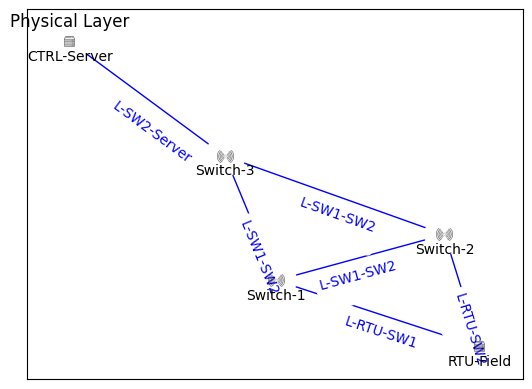

In [3]:
# Physical view: devices and nodes connected by links
create_plot(net, draw_type='dev')
plt.title('Physical Layer')
plt.show()

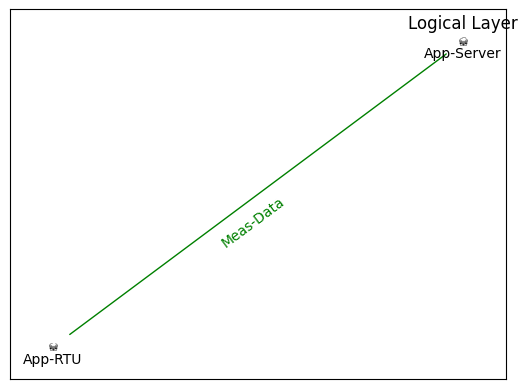

In [4]:
# Logical view: apps connected by end-to-end connections
create_plot(net, draw_type='app')
plt.title('Logical Layer')
plt.show()

## 3. Inspect and validate

In [4]:
passed = pi.inspect(net, verbose=True)
print('Validation passed:', passed)

----------- INSPECTION PASSED -----------
Validation passed: True


In [5]:
# Peek at the raw DataFrames
print('--- Nodes ---')
display(net.node[['name', 'type']])
print('\n--- Links ---')
display(net.link[['name', 'type']])

--- Nodes ---


,name,type
0,Switch-1,NodeType.SWITCH
1,Switch-2,NodeType.SWITCH
2,Switch-3,NodeType.SWITCH



--- Links ---


,name,type
0,L-RTU-SW1,LAN1000
1,L-RTU-SW2,LAN1000
2,L-SW1-SW2,LAN1000
3,L-SW1-SW2,LAN1000
4,L-SW1-SW2,LAN1000
5,L-SW2-Server,LAN1000


## 4. Bonus: Monte Carlo reliability (teaser)

pandaict includes a powerful Monte Carlo engine for reliability analysis. A dedicated tutorial series covers it in detail; here we only scratch the surface.

Running 20000000 (100000 x 200) simulations in parallel...


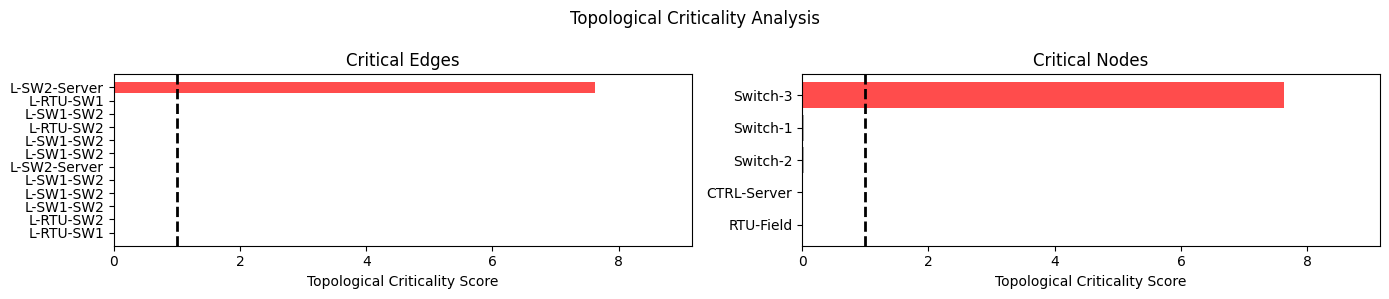

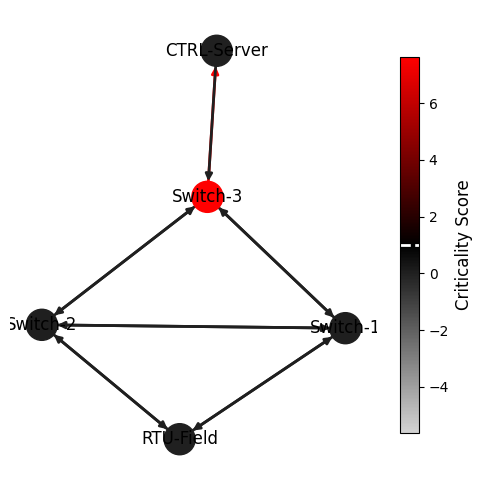

MTTF: 4135.9 h
MTTR: 12.4 h
MTBF: 4148.3 h


In [6]:
from pandaict.reliability.reliability import analyze_critical_components_for_conn, plot_graph

result = analyze_critical_components_for_conn(net, [conn], verbose=False)
plot_graph(net, edge_criticality=result.get("edge_criticality"), node_criticality=result.get("node_criticality"))

print(f"MTTF: {result['mttf_h']:.1f} h")
print(f"MTTR: {result['mttr_h']:.1f} h")
print(f"MTBF: {result['mtbf_h']:.1f} h")

## Where to go from here

| Notebook | Topic |
|----------|-------|
| **01** | Concepts & abstraction layers (ISO/OSI mapping, element types) |
| **02** | Physical layer in depth (nodes, devices, links) |
| **03** | Logical layer in depth (apps, connections, converters) |
| **04** | Calculations & workflows (routing, MTBF, BER, data volumes) |
| **05** | Inspection, debugging & file I/O |
| **06** | Standard types & custom enums |
| **07** | Advanced topics (UUIDs, IP addressing, connectors, best practices) |

The **[reliability Monte Carlo series](../monte_carlo-Notebooks/00_how_to_MTTF_networkX.ipynb)** is the place to go for deep dives into stochastic reliability analysis.